# Credit Risk Assessment & Loan Default Prediction
**Goal:** find out what makes a borrower default on a loan, and predict defaults using two models: Logistic Regression and Random Forest.

**Data:** 32,581 loans. The target column is `loan_status` (1 = default, 0 = repaid).

**Steps:** 1. Understand data → 2. Clean → 3. EDA → 4. Statistics → 5. Features → 6. Models → 7. Evaluation → 8. Conclusions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

os.makedirs("visualizations", exist_ok=True)   # folder to save charts

## 1. Data understanding

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
# Column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [4]:
# Missing values and duplicates
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Duplicate rows: 165


In [5]:
# Summary statistics of numeric columns
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


**What we see:**
- 7 numeric columns and 4 text (categorical) columns.
- Missing values in `loan_int_rate` and `person_emp_length`.
- 165 duplicate rows.
- Impossible values: max age is 144 and max employment length is 123 years.
- The target `loan_status` is 1 for defaults. Only about 22% of loans default (imbalanced data).

## 2. Data cleaning

In [6]:
print("Rows before cleaning:", len(df))

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Remove impossible ages (older than 100)
df = df[df.person_age <= 100]

# 3. Remove impossible employment length (more than 60 years)
#    (rows with missing employment length are kept for now)
df = df[(df.person_emp_length <= 60) | (df.person_emp_length.isnull())]

df = df.reset_index(drop=True)
print("Rows after cleaning:", len(df))

Rows before cleaning: 32581
Rows after cleaning: 32409


In [7]:
# Handle missing values: fill with the median (middle value).
# First, remember which employment lengths were missing - this turns out to be a useful signal.
df["emp_missing"] = df.person_emp_length.isnull().astype(int)

# NOTE: we fill the missing values later, AFTER splitting into train and test,
# using only the training data. This avoids "data leakage".
print(df[["person_emp_length", "loan_int_rate"]].isnull().sum())

person_emp_length     887
loan_int_rate        3094
dtype: int64


**Cleaning summary:**
- Removed 165 duplicates, 5 impossible ages and 2 impossible employment lengths.
- Missing values will be filled with the median after the train/test split.
- Very high incomes are real borrowers, so we keep them and use a log transform later.

## 3. Exploratory Data Analysis (EDA)

### Univariate analysis (one column at a time)

loan_status
0    25321
1     7088
Name: count, dtype: int64

Default rate: 21.9 %


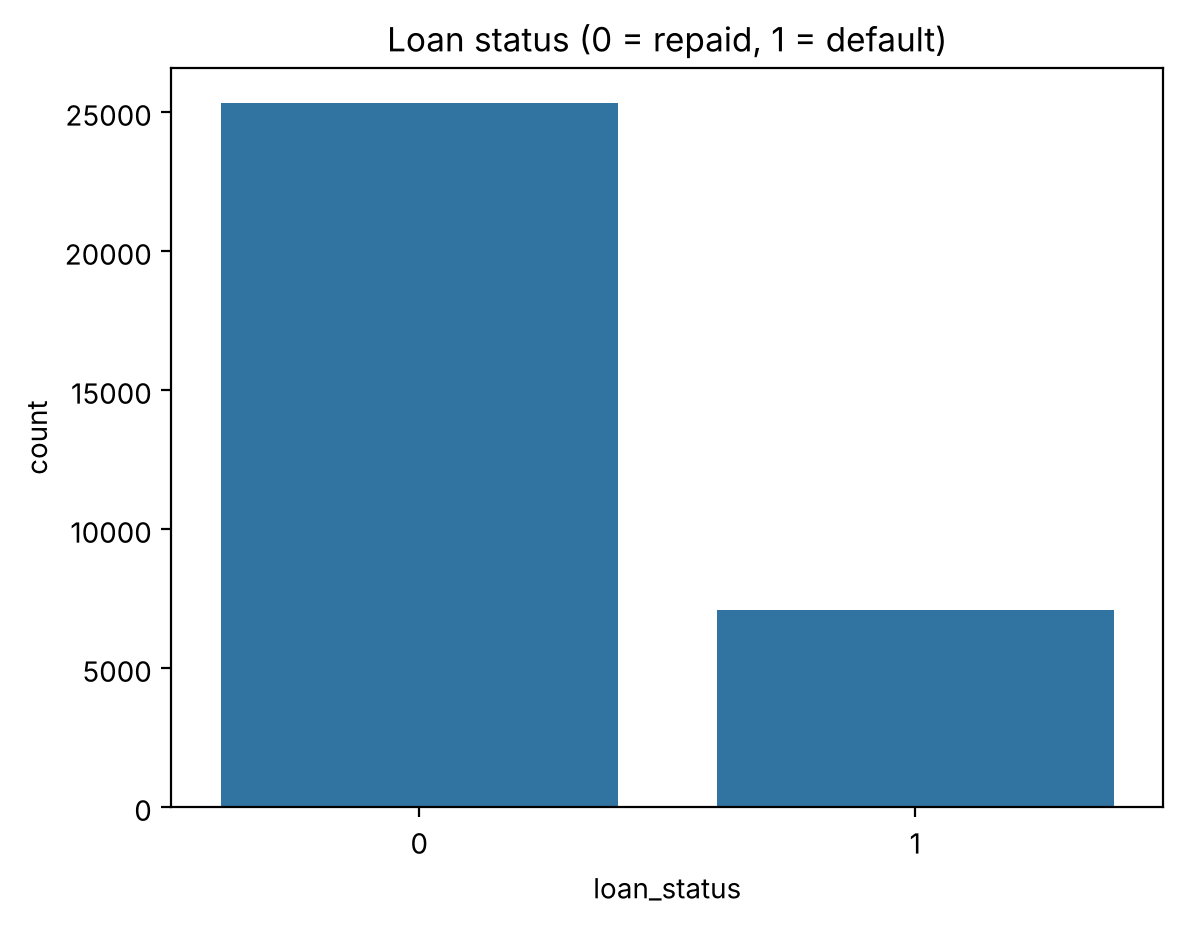

In [8]:
# How many loans default?
print(df.loan_status.value_counts())
print()
print("Default rate:", round(df.loan_status.mean() * 100, 1), "%")

sns.countplot(x="loan_status", data=df)
plt.title("Loan status (0 = repaid, 1 = default)")
plt.savefig("visualizations/01_loan_status.png", bbox_inches="tight")
plt.show()

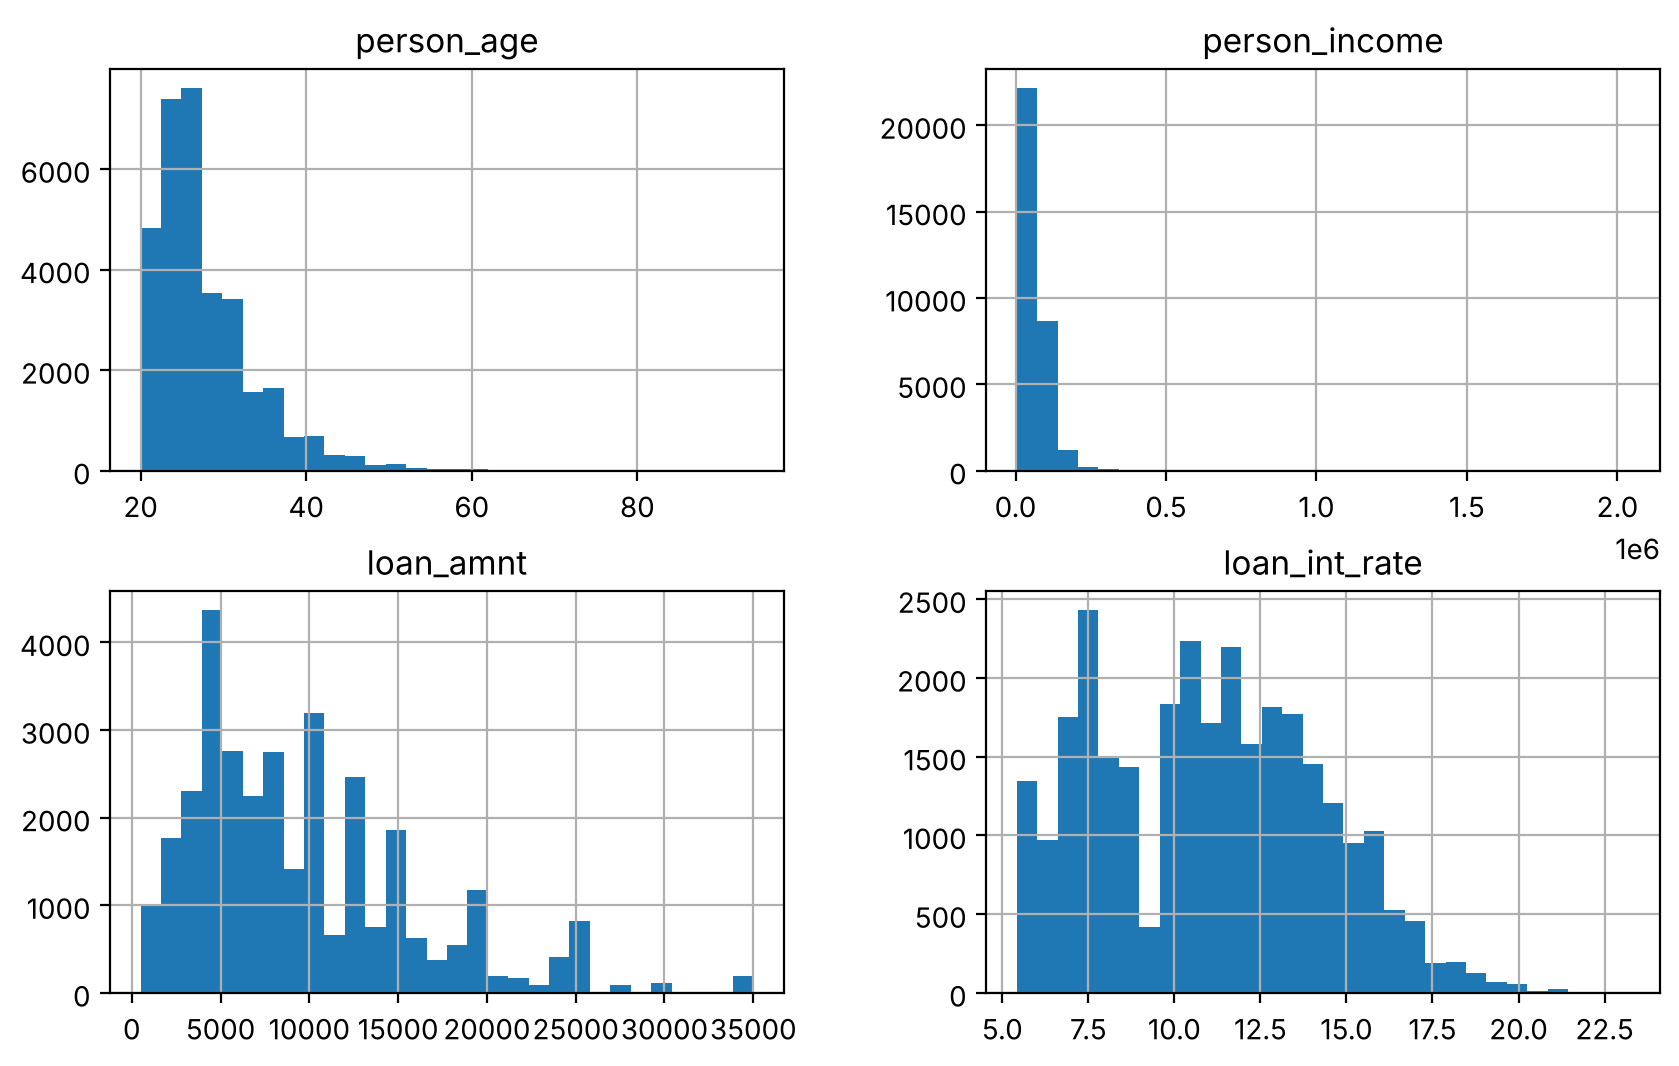

In [9]:
# Distribution of the main numeric columns
df[["person_age", "person_income", "loan_amnt", "loan_int_rate"]].hist(bins=30, figsize=(10, 6))
plt.savefig("visualizations/02_numeric_distributions.png", bbox_inches="tight")
plt.show()

Income and age are right-skewed (a few very high values). About 22% of loans default.

### Bivariate analysis (each feature vs default)

loan_grade
A    10.0
B    16.3
C    20.8
D    59.0
E    64.5
F    70.5
G    98.4
Name: loan_status, dtype: float64


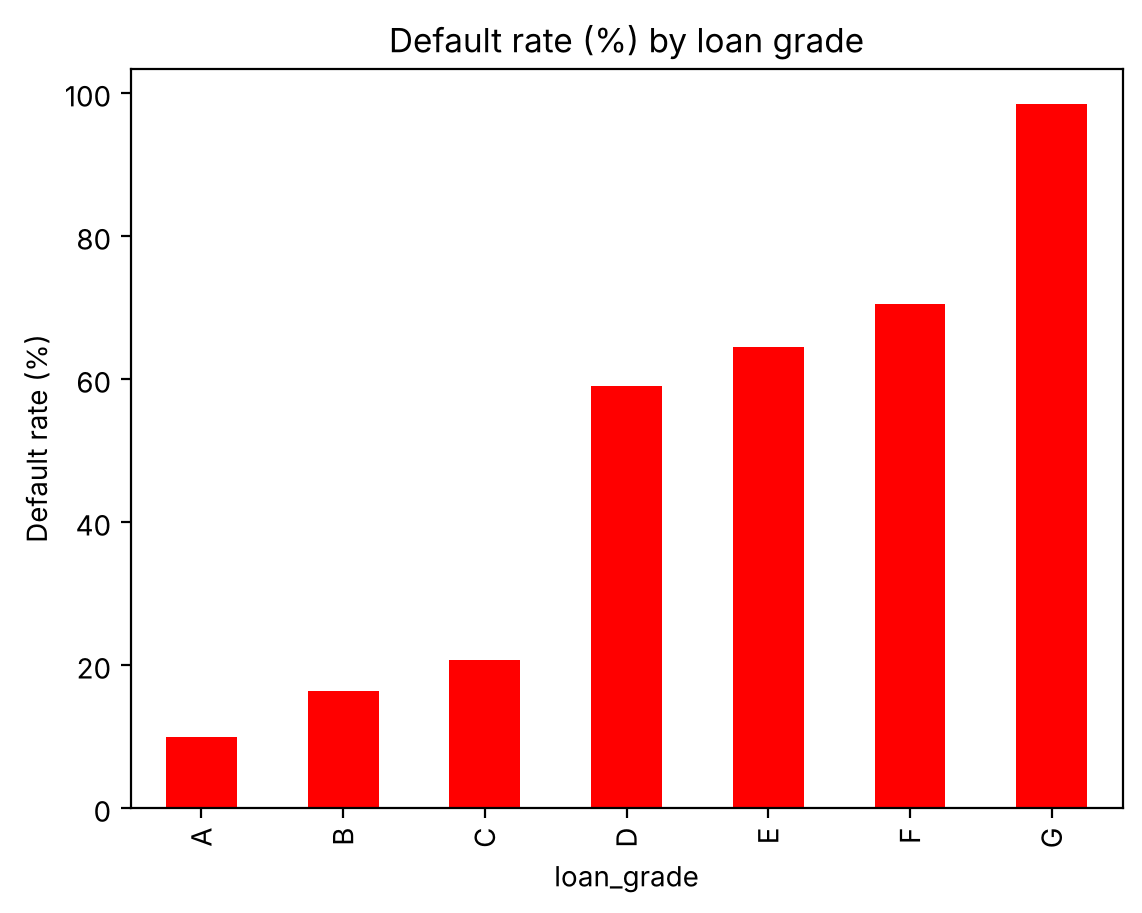

In [10]:
# Default rate by loan grade
grade_rate = df.groupby("loan_grade").loan_status.mean() * 100
print(grade_rate.round(1))

grade_rate.plot(kind="bar", color="red")
plt.title("Default rate (%) by loan grade")
plt.ylabel("Default rate (%)")
plt.savefig("visualizations/03_default_by_grade.png", bbox_inches="tight")
plt.show()

person_home_ownership
MORTGAGE    12.6
OTHER       31.1
OWN          7.5
RENT        31.6
Name: loan_status, dtype: float64


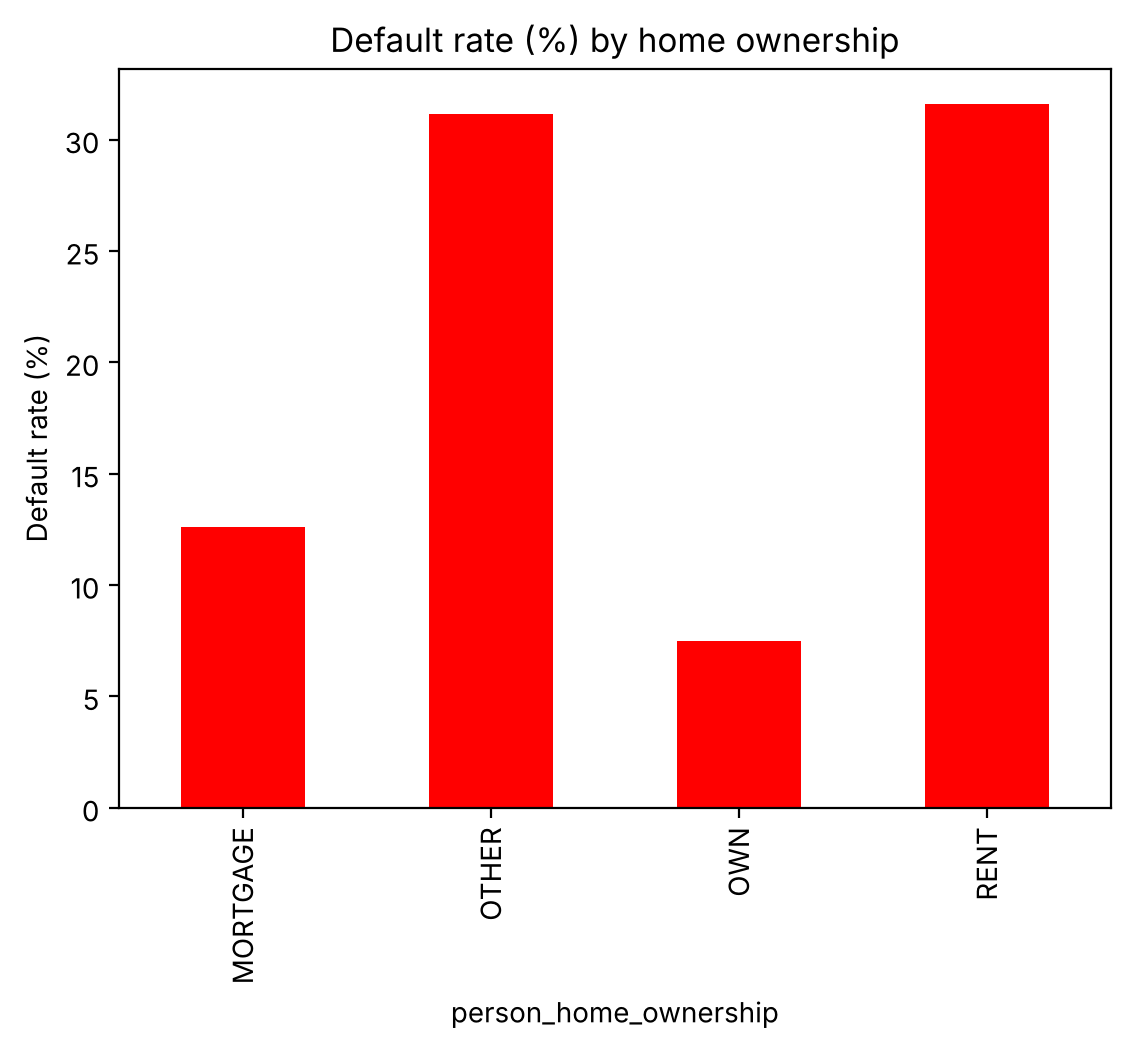

In [11]:
# Default rate by home ownership
home_rate = df.groupby("person_home_ownership").loan_status.mean() * 100
print(home_rate.round(1))

home_rate.plot(kind="bar", color="red")
plt.title("Default rate (%) by home ownership")
plt.ylabel("Default rate (%)")
plt.savefig("visualizations/04_default_by_home_ownership.png", bbox_inches="tight")
plt.show()

loan_intent
DEBTCONSOLIDATION    28.7
EDUCATION            17.3
HOMEIMPROVEMENT      26.2
MEDICAL              26.8
PERSONAL             19.9
VENTURE              14.9
Name: loan_status, dtype: float64


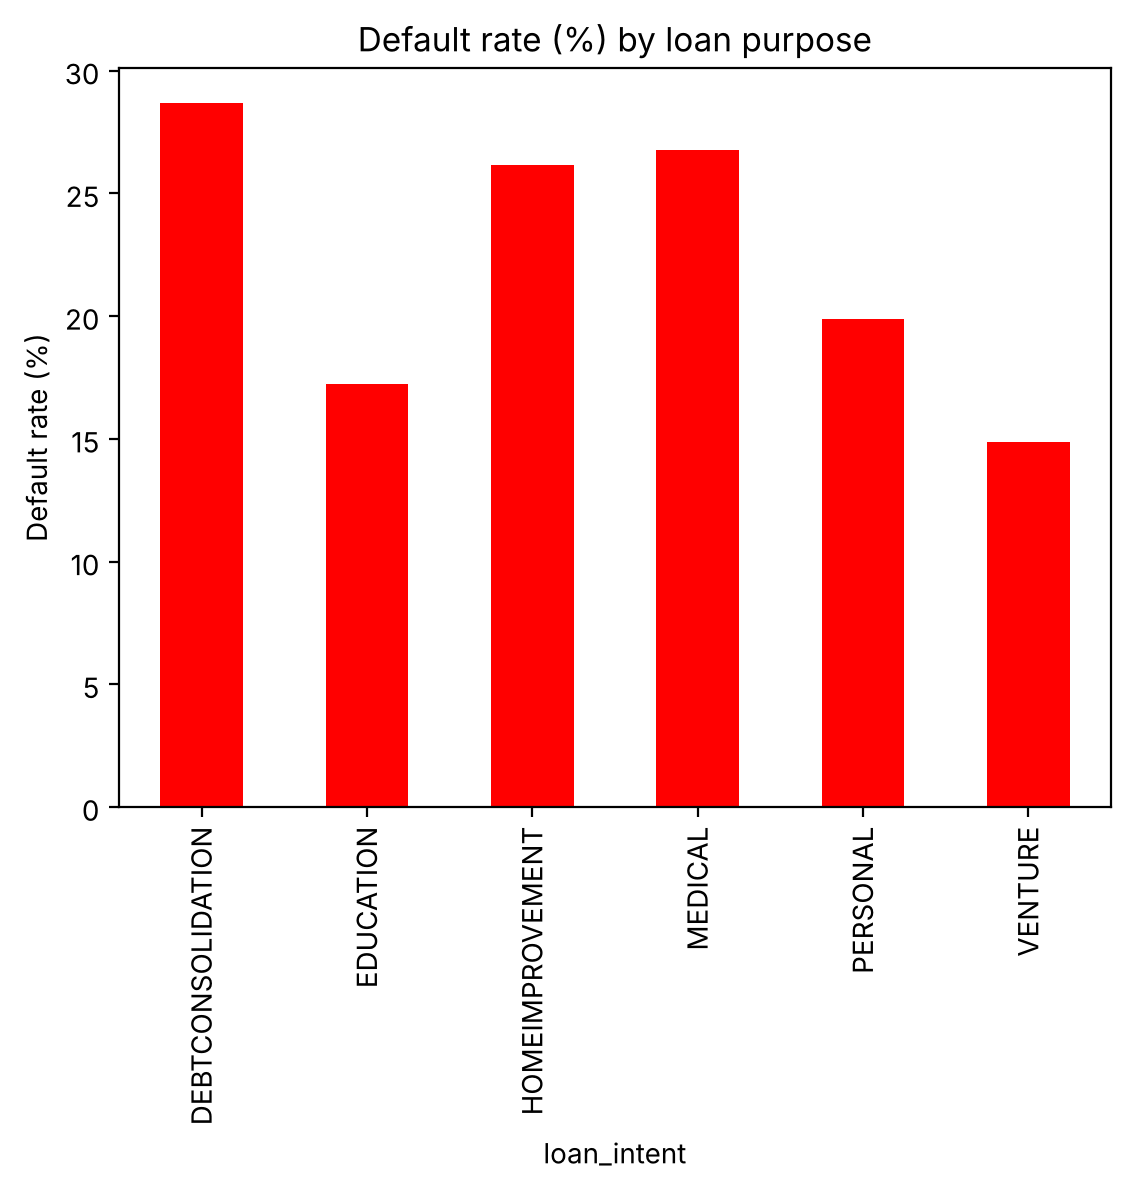

In [12]:
# Default rate by loan purpose
intent_rate = df.groupby("loan_intent").loan_status.mean() * 100
print(intent_rate.round(1))

intent_rate.plot(kind="bar", color="red")
plt.title("Default rate (%) by loan purpose")
plt.ylabel("Default rate (%)")
plt.savefig("visualizations/05_default_by_loan_intent.png", bbox_inches="tight")
plt.show()

dti_range
0-10%     11.8
10-20%    15.1
20-30%    22.0
30-40%    68.9
40%+      74.2
Name: loan_status, dtype: float64


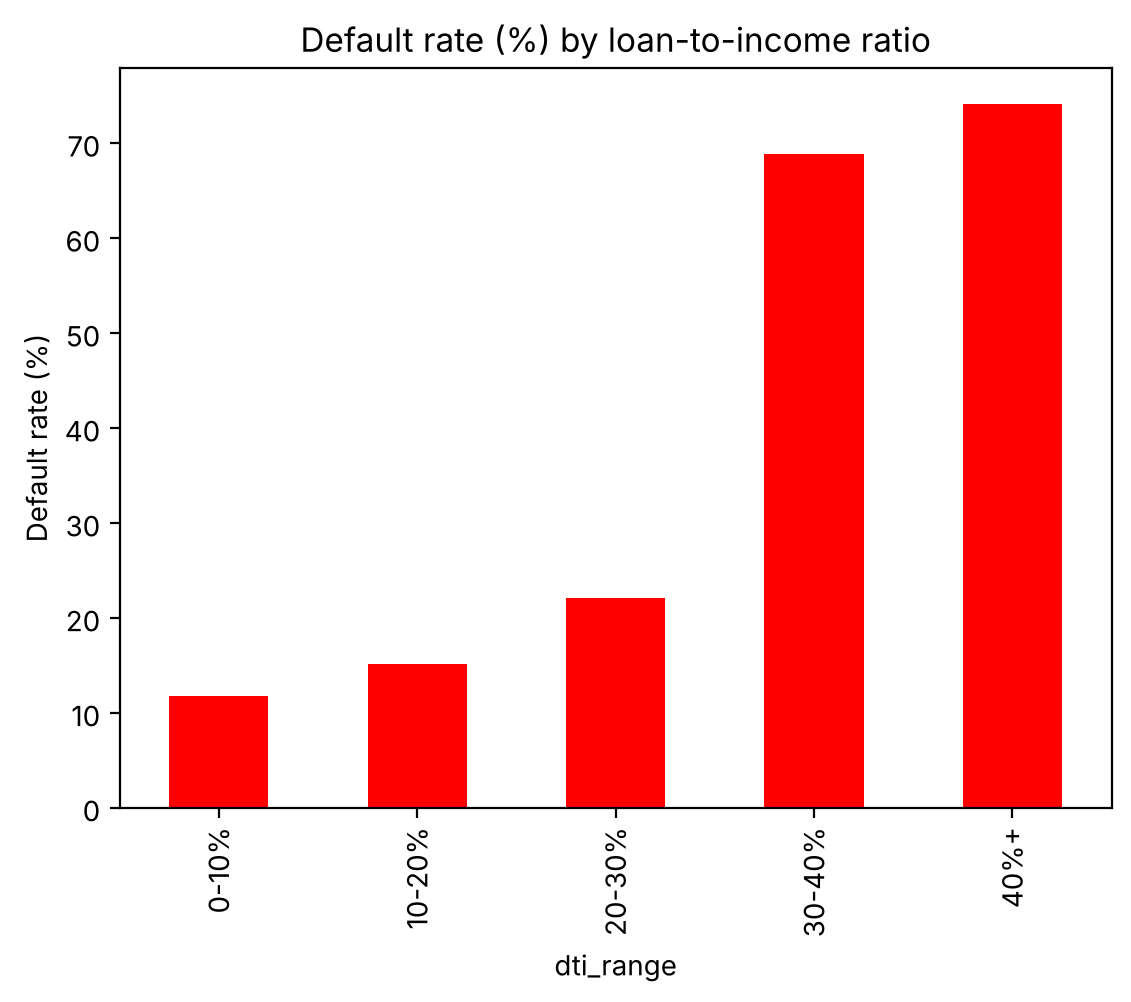

In [13]:
# Default rate by loan-to-income ratio (grouped into ranges)
df["dti_range"] = pd.cut(df.loan_percent_income, bins=[0, 0.1, 0.2, 0.3, 0.4, 1],
                         labels=["0-10%", "10-20%", "20-30%", "30-40%", "40%+"])
dti_rate = df.groupby("dti_range").loan_status.mean() * 100
print(dti_rate.round(1))

dti_rate.plot(kind="bar", color="red")
plt.title("Default rate (%) by loan-to-income ratio")
plt.ylabel("Default rate (%)")
plt.savefig("visualizations/06_default_by_loan_to_income.png", bbox_inches="tight")
plt.show()

income_group
Lowest     43.3
Low        23.5
Middle     18.3
High       14.6
Highest     9.2
Name: loan_status, dtype: float64


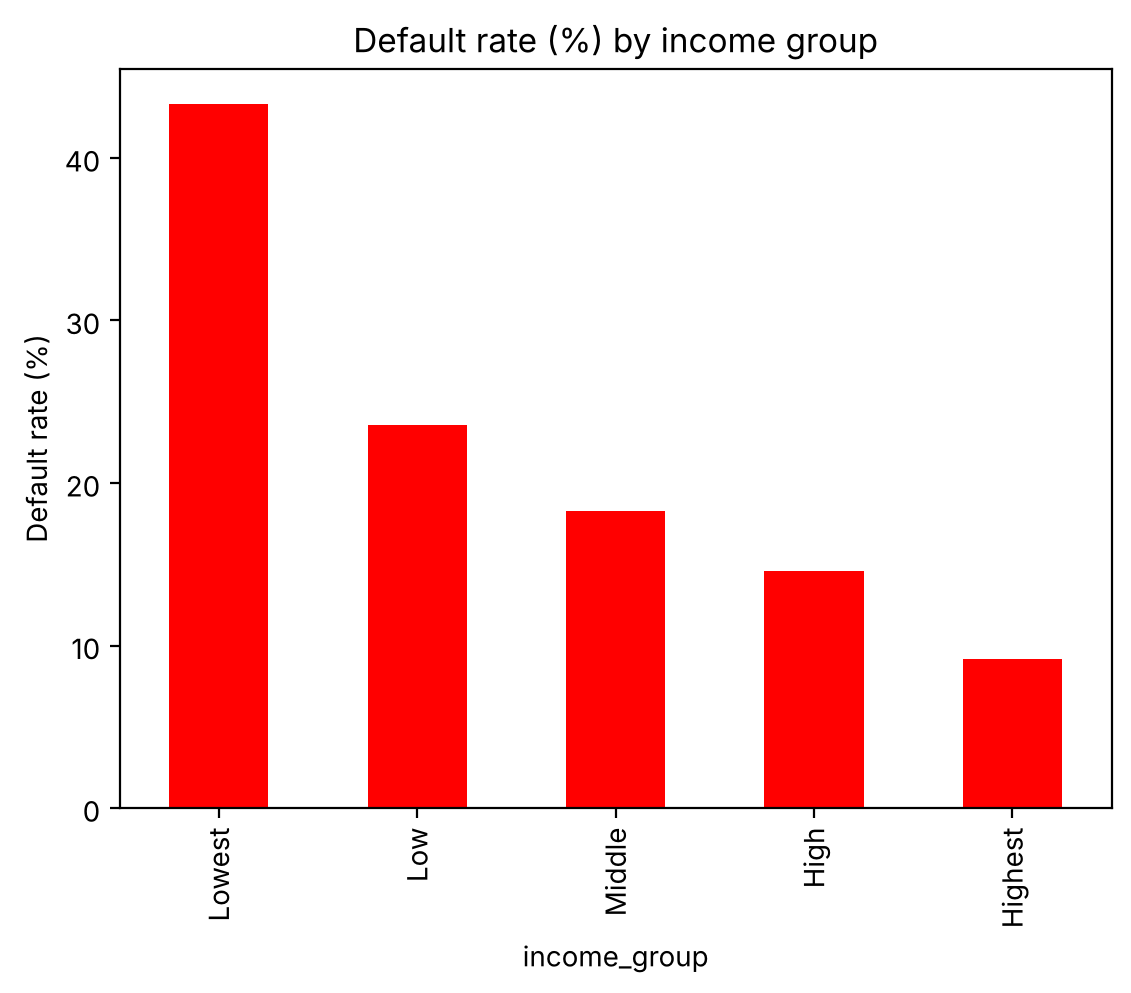

In [14]:
# Default rate by income group (5 equal-sized groups)
df["income_group"] = pd.qcut(df.person_income, 5, labels=["Lowest", "Low", "Middle", "High", "Highest"])
income_rate = df.groupby("income_group").loan_status.mean() * 100
print(income_rate.round(1))

income_rate.plot(kind="bar", color="red")
plt.title("Default rate (%) by income group")
plt.ylabel("Default rate (%)")
plt.savefig("visualizations/07_default_by_income.png", bbox_inches="tight")
plt.show()

In [15]:
# Prior default on file
print((df.groupby("cb_person_default_on_file").loan_status.mean() * 100).round(1))

cb_person_default_on_file
N    18.4
Y    37.9
Name: loan_status, dtype: float64


**Key patterns:**
- **Loan grade:** default rate rises from 10% (A) to 59% (D) and 98% (G).
- **Loan-to-income:** about 12-22% default below 30%, but about 70% above 30%.
- **Income:** the lowest income group defaults at 43% vs 9% for the highest.
- **Home ownership:** renters 32%, mortgage 13%, owners 7.5%.
- **Prior default on file:** 38% default vs 18% without.
- **Loan purpose:** debt consolidation, medical and home improvement are riskiest; venture is safest.

### Multivariate analysis (several columns together)

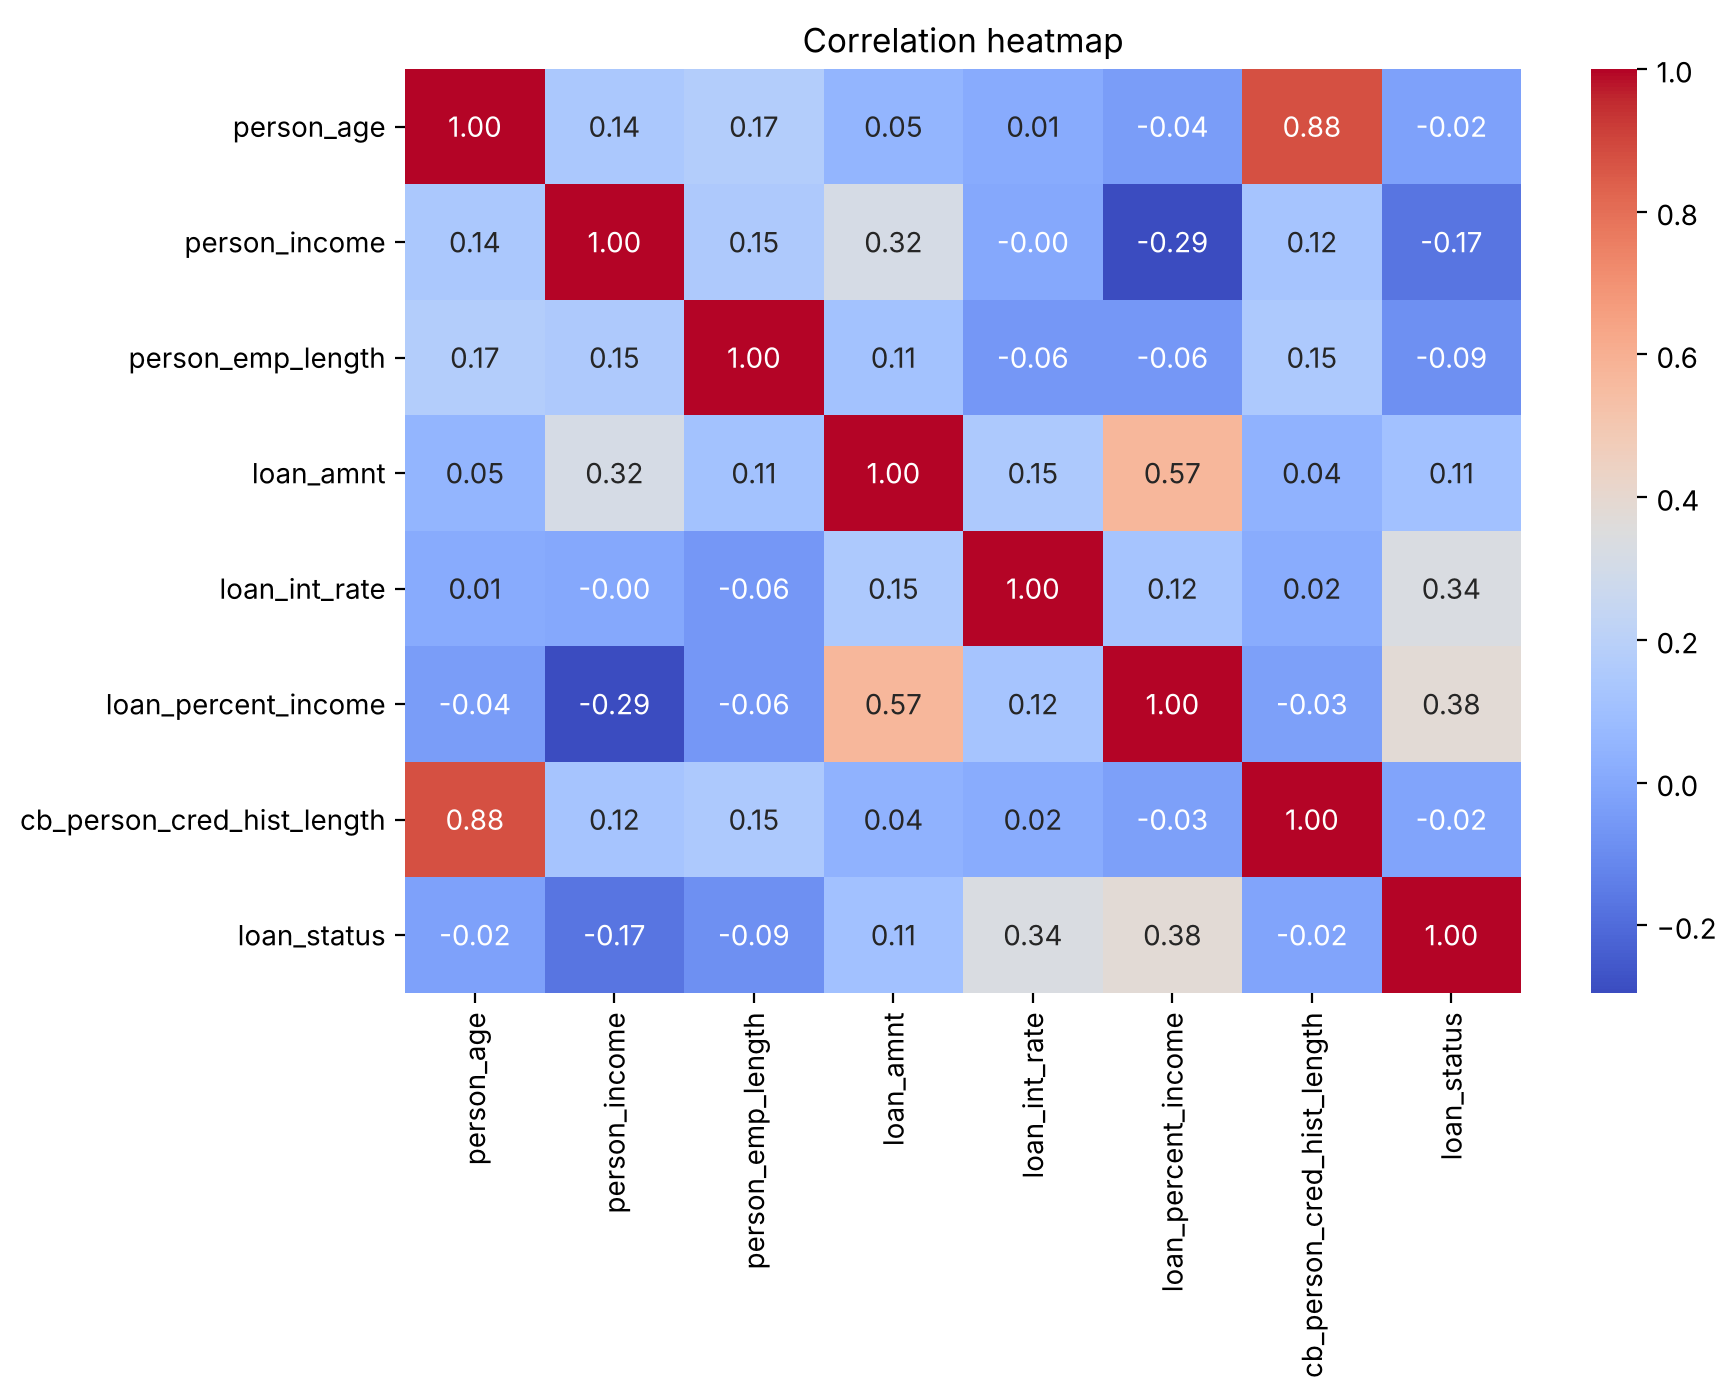

In [16]:
# Correlation between numeric columns and default
numeric_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
                "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length", "loan_status"]

plt.figure(figsize=(9, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.savefig("visualizations/08_correlation_heatmap.png", bbox_inches="tight")
plt.show()

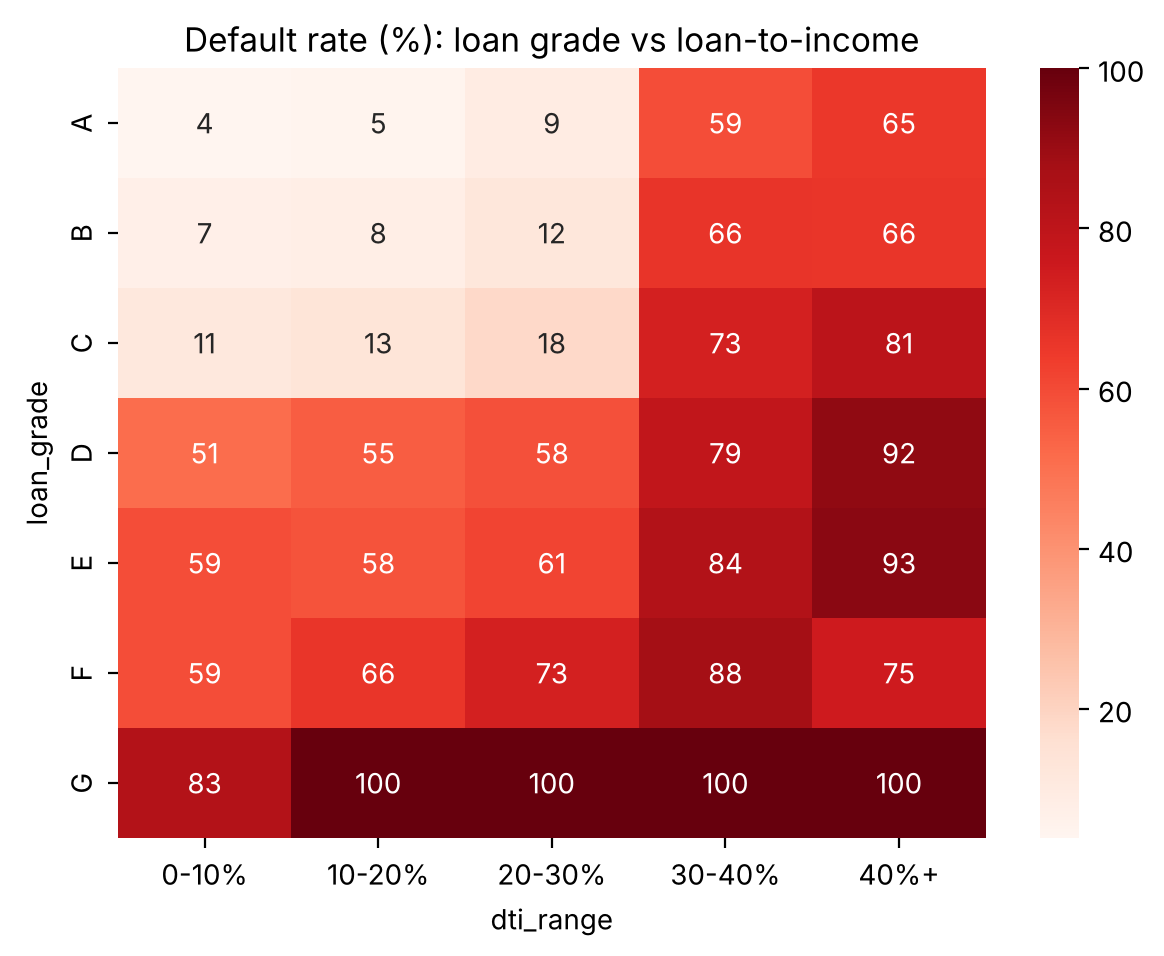

In [17]:
# Default rate by loan grade AND loan-to-income range together
table = df.pivot_table(index="loan_grade", columns="dti_range", values="loan_status", aggfunc="mean") * 100

plt.figure(figsize=(7, 5))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Reds")
plt.title("Default rate (%): loan grade vs loan-to-income")
plt.savefig("visualizations/09_grade_vs_loan_to_income.png", bbox_inches="tight")
plt.show()

**Takeaway:** interest rate, loan-to-income and income have the strongest link to default. Age and credit history barely matter. Risk adds up: a high loan-to-income ratio on a grade D or worse loan almost always defaults.

## 4. Statistical analysis

### Descriptive statistics: defaulted vs repaid loans

In [18]:
# Average of each numeric column for repaid (0) and default (1) loans
df.groupby("loan_status")[numeric_cols[:-1]].mean().round(2)

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length
loan_status,,,,,,,
0,27.80,70597.36,4.97,9239.34,10.44,0.15,5.85
1,27.48,49093.10,4.12,10854.07,13.07,0.25,5.69


### Hypothesis test for numeric columns
- **Question:** is the column different for defaulted and repaid loans?
- **Test:** Mann-Whitney U test (works well for skewed data like income).
- **Rule:** p-value below 0.05 means the difference is real (statistically significant).
- **Effect size:** the p-value is tiny for almost everything because we have lots of data, so we also measure *how big* the difference is (difference in means divided by the standard deviation).

In [19]:
defaulted = df[df.loan_status == 1]
repaid = df[df.loan_status == 0]

for col in numeric_cols[:-1]:
    p_value = stats.mannwhitneyu(defaulted[col].dropna(), repaid[col].dropna()).pvalue
    effect = (defaulted[col].mean() - repaid[col].mean()) / df[col].std()
    print(col, "| p-value:", round(p_value, 4), "| effect size:", round(effect, 2))

person_age | p-value: 0.0 | effect size: -0.05
person_income | p-value: 0.0 | effect size: -0.41
person_emp_length | p-value: 0.0 | effect size: -0.21
loan_amnt | p-value: 0.0 | effect size: 0.26
loan_int_rate | p-value: 0.0 | effect size: 0.81
loan_percent_income | p-value: 0.0 | effect size: 0.92
cb_person_cred_hist_length | p-value: 0.0 | effect size: -0.04


All p-values are below 0.05 (printed as 0.0 because they are extremely small), but the effect sizes tell the real story: **loan-to-income (about 0.9) and interest rate (about 0.8) have a large effect**, income and loan amount a small effect, age and credit history almost none.

### Chi-square test for categorical columns
- **Question:** is the column related to default?
- **Cramér's V** measures the strength (0 = no link, 1 = perfect link).

In [20]:
categorical_cols = ["loan_grade", "person_home_ownership", "loan_intent", "cb_person_default_on_file"]

for col in categorical_cols:
    counts = pd.crosstab(df[col], df.loan_status)
    chi2, p_value, dof, expected = stats.chi2_contingency(counts)
    cramers_v = np.sqrt(chi2 / len(df))     # simple version for a 2-class target
    print(col, "| p-value:", round(p_value, 4), "| Cramer's V:", round(cramers_v, 2))

loan_grade | p-value: 0.0 | Cramer's V: 0.42
person_home_ownership | p-value: 0.0 | Cramer's V: 0.24
loan_intent | p-value: 0.0 | Cramer's V: 0.13
cb_person_default_on_file | p-value: 0.0 | Cramer's V: 0.18


All four are significantly related to default. Loan grade has the strongest link (V about 0.4), then home ownership, prior default and loan purpose.

## 5. Feature engineering

In [21]:
# Create new useful columns
df["log_income"] = np.log(df.person_income)                              # shrink very large incomes
df["grade_number"] = df.loan_grade.map({"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7})  # grade as number
df["prior_default"] = (df.cb_person_default_on_file == "Y").astype(int)  # Y/N -> 1/0
df["high_loan_to_income"] = (df.loan_percent_income >= 0.30).astype(int)  # the 30% threshold we saw in EDA

# Choose the columns the models will use
features = ["person_age", "log_income", "person_emp_length", "loan_amnt", "loan_int_rate",
            "loan_percent_income", "cb_person_cred_hist_length", "grade_number",
            "prior_default", "high_loan_to_income", "emp_missing",
            "person_home_ownership", "loan_intent"]

# Turn text columns (home ownership, loan purpose) into 0/1 columns
X = pd.get_dummies(df[features], drop_first=True)
y = df.loan_status
print("Number of model features:", X.shape[1])
X.head()

Number of model features: 19


,person_age,log_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,grade_number,prior_default,high_loan_to_income,emp_missing,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,21,9.169518,5.0,1000,11.14,0.10,2,2,0,0,0,False,True,False,True,False,False,False,False
1,25,9.169518,1.0,5500,12.87,0.57,3,3,0,1,0,False,False,False,False,False,True,False,False
2,23,11.089805,4.0,35000,15.23,0.53,2,3,0,1,0,False,False,True,False,False,True,False,False
3,24,10.904119,8.0,35000,14.27,0.55,4,3,1,1,0,False,False,True,False,False,True,False,False
4,21,9.200290,2.0,2500,7.14,0.25,2,1,0,0,0,False,True,False,False,False,False,False,True


In [22]:
# Split into training (80%) and testing (20%) data.
# stratify=y keeps the same default rate in both parts.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Fill missing values with the median of the TRAINING data
for col in ["person_emp_length", "loan_int_rate"]:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

# Scale the numbers (needed for Logistic Regression, not for Random Forest)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Default rate in train:", round(y_train.mean(), 3), "| in test:", round(y_test.mean(), 3))

Training rows: 25927 | Test rows: 6482
Default rate in train: 0.219 | in test: 0.219


**What we did:** created log income, a numeric grade, a prior-default flag and a "30% or more loan-to-income" flag; converted text columns to 0/1; split 80/20; filled missing values using only training data; scaled the numbers for Logistic Regression.

## 6. Machine learning models
Only 22% of loans default (imbalanced data). We use `class_weight="balanced"` so the models pay more attention to defaults.

In [23]:
# Model 1: Logistic Regression (uses scaled data)
log_reg = LogisticRegression(class_weight="balanced", max_iter=1000)

# Model 2: Random Forest (uses unscaled data)
rand_forest = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)

## 7. Model evaluation

### Cross-validation (5 folds on the training data)

In [24]:
metrics = ["accuracy", "precision", "recall", "f1"]

cv_lr = cross_validate(log_reg, X_train_scaled, y_train, cv=5, scoring=metrics)
cv_rf = cross_validate(rand_forest, X_train, y_train, cv=5, scoring=metrics)

print("Logistic Regression CV F1:", cv_lr["test_f1"].mean().round(3))
print("Random Forest CV F1:      ", cv_rf["test_f1"].mean().round(3))

Logistic Regression CV F1: 0.648
Random Forest CV F1:       0.816


### Final test on unseen data

In [25]:
# Train both models and predict on the test set
log_reg.fit(X_train_scaled, y_train)
rand_forest.fit(X_train, y_train)

lr_pred = log_reg.predict(X_test_scaled)
rf_pred = rand_forest.predict(X_test)

lr_prob = log_reg.predict_proba(X_test_scaled)[:, 1]
rf_prob = rand_forest.predict_proba(X_test)[:, 1]

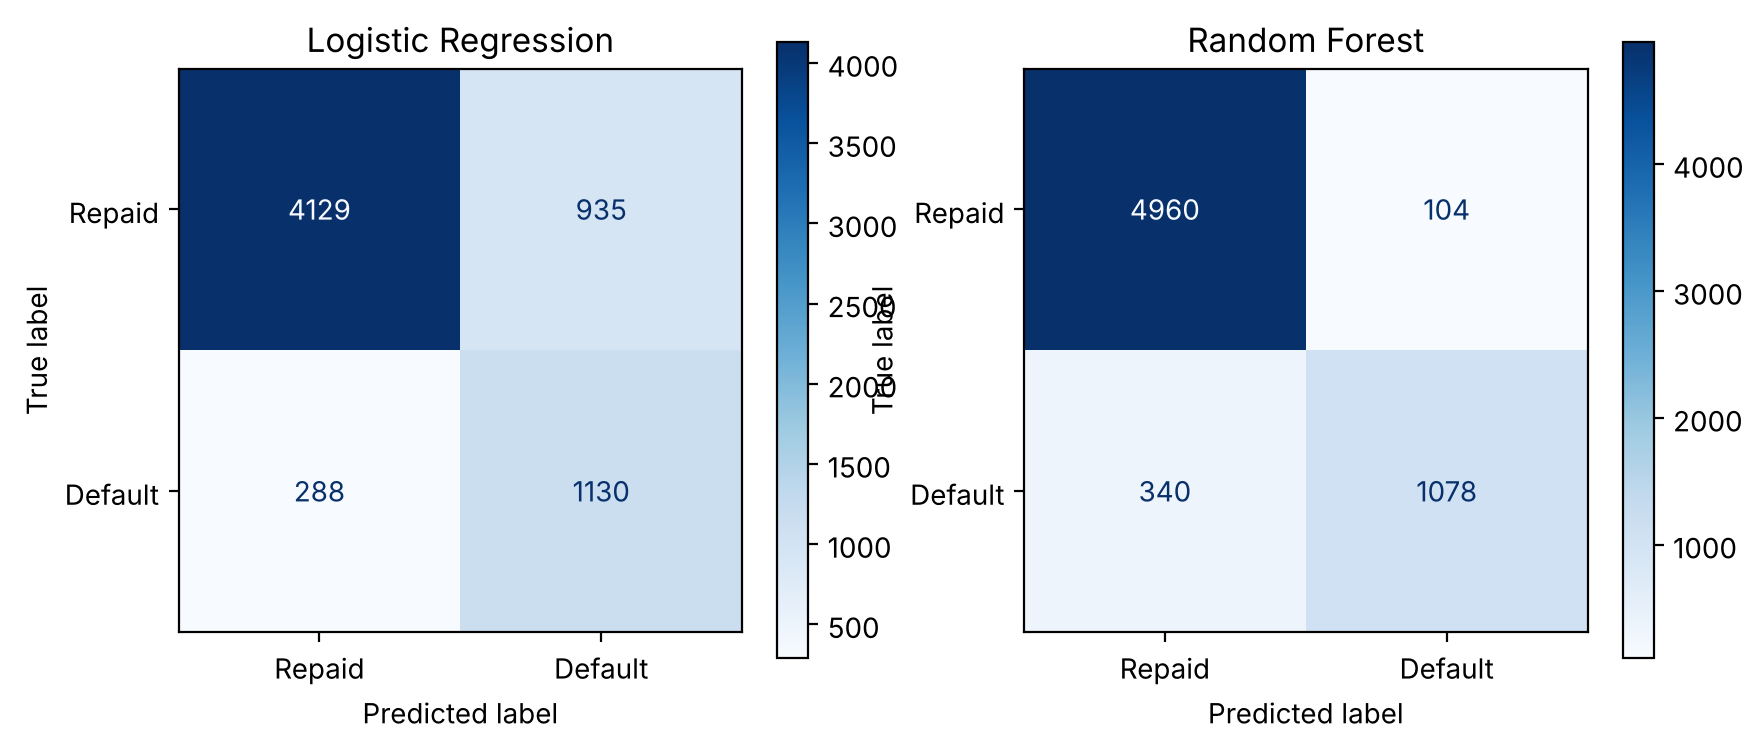

In [26]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, lr_pred), display_labels=["Repaid", "Default"]).plot(ax=axes[0], cmap="Blues")
ConfusionMatrixDisplay(confusion_matrix(y_test, rf_pred), display_labels=["Repaid", "Default"]).plot(ax=axes[1], cmap="Blues")
axes[0].set_title("Logistic Regression")
axes[1].set_title("Random Forest")
plt.savefig("visualizations/10_confusion_matrices.png", bbox_inches="tight")
plt.show()

In [27]:
# Build the comparison table
tn1, fp1, fn1, tp1 = confusion_matrix(y_test, lr_pred).ravel()
tn2, fp2, fn2, tp2 = confusion_matrix(y_test, rf_pred).ravel()

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "CV_F1": [cv_lr["test_f1"].mean(), cv_rf["test_f1"].mean()],
    "Accuracy": [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
    "Precision": [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    "Recall": [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred)],
    "F1_Score": [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)],
    "ROC_AUC": [roc_auc_score(y_test, lr_prob), roc_auc_score(y_test, rf_prob)],
    "True_Negatives": [tn1, tn2], "False_Positives": [fp1, fp2],
    "False_Negatives": [fn1, fn2], "True_Positives": [tp1, tp2],
})
comparison = comparison.round(3)
comparison.to_csv("Model_Comparison.csv", index=False)
comparison

,Model,CV_F1,Accuracy,Precision,Recall,F1_Score,ROC_AUC,True_Negatives,False_Positives,False_Negatives,True_Positives
0,Logistic Regression,0.648,0.811,0.547,0.797,0.649,0.882,4129,935,288,1130
1,Random Forest,0.816,0.932,0.912,0.760,0.829,0.938,4960,104,340,1078


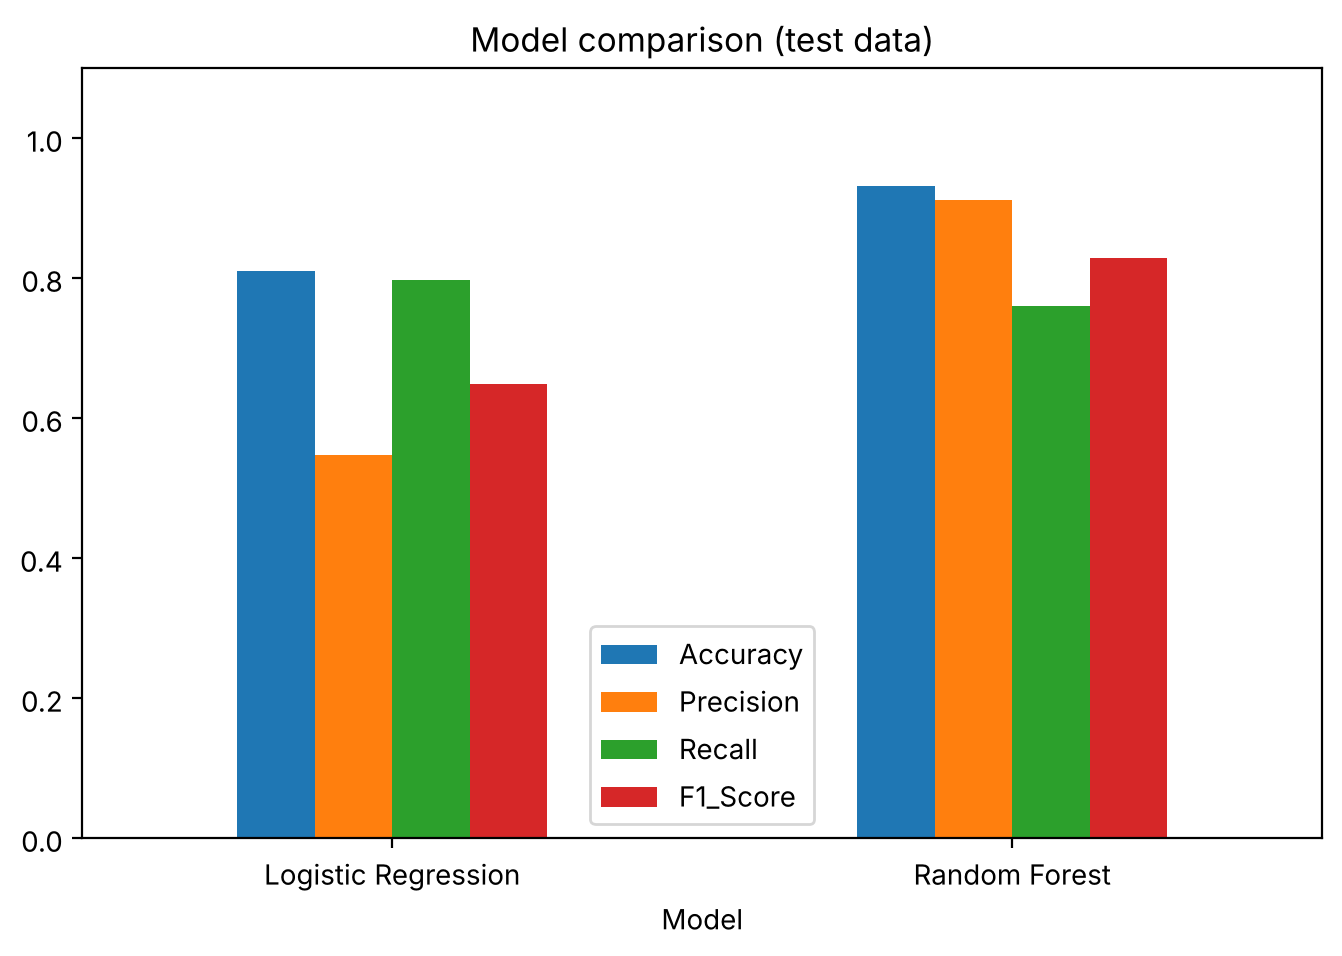

In [28]:
# Compare the models visually
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1_Score"]].plot(kind="bar", figsize=(8, 5))
plt.title("Model comparison (test data)")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.savefig("visualizations/11_model_comparison.png", bbox_inches="tight")
plt.show()

**How to read the metrics:**
- **Accuracy:** share of all predictions that are right.
- **Precision:** when the model says "default", how often it is right.
- **Recall:** of all real defaults, how many the model catches.
- **F1-score:** one number balancing precision and recall (best for imbalanced data).

### Which factors matter most? (Random Forest)

log_income                    0.156
loan_percent_income           0.148
grade_number                  0.134
loan_int_rate                 0.122
loan_amnt                     0.072
high_loan_to_income           0.070
person_emp_length             0.054
person_home_ownership_RENT    0.052
dtype: float64


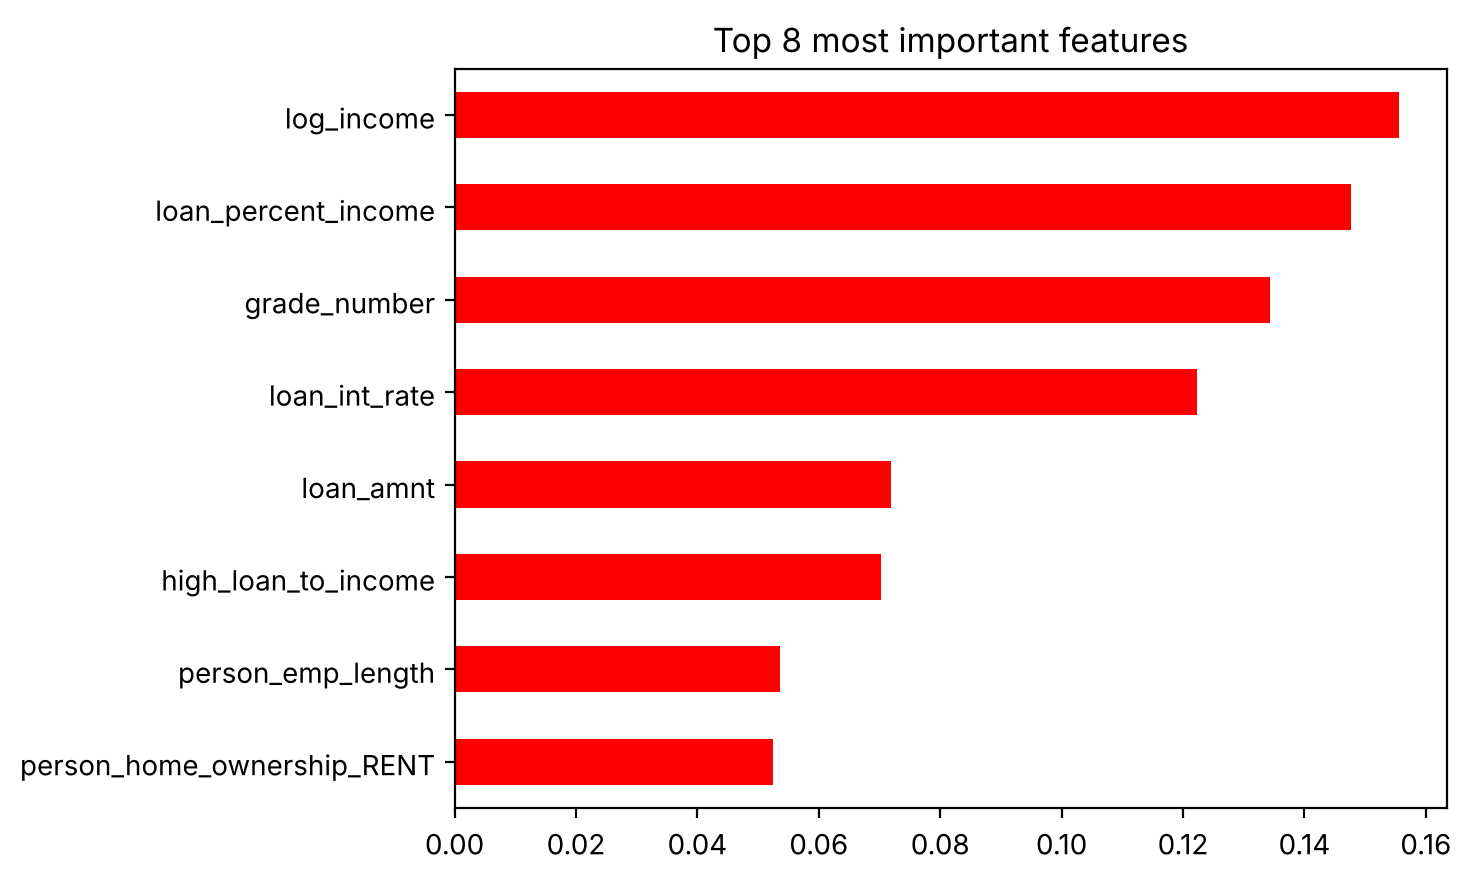

In [29]:
importance = pd.Series(rand_forest.feature_importances_, index=X_train.columns)
top = importance.sort_values(ascending=False).head(8)
print(top.round(3))

top.sort_values().plot(kind="barh", color="red")
plt.title("Top 8 most important features")
plt.savefig("visualizations/12_feature_importance.png", bbox_inches="tight")
plt.show()

## 8. Conclusions

**Model results (test set, 6,482 loans):**

| Metric | Logistic Regression | Random Forest |
|---|---|---|
| Accuracy | 0.811 | **0.932** |
| Precision | 0.547 | **0.912** |
| Recall | **0.797** | 0.760 |
| F1-score | 0.649 | **0.829** |
| ROC-AUC | 0.882 | **0.938** |

- **Random Forest is the better model.** It wrongly flags only 104 good borrowers as risky, compared with 935 for Logistic Regression.
- **Logistic Regression catches slightly more defaults** (recall 0.80 vs 0.76) but has low precision (0.55), so about half of its "default" predictions are wrong.
- Cross-validation F1 (0.65 and 0.82) is close to the test F1, so the results are stable.

**Most important factors for default:** income, loan-to-income ratio, loan grade and interest rate. Age and credit history length matter very little.

**Business takeaway:** loans with a loan-to-income ratio above 30%, grade D or worse, low income, renters and prior defaulters deserve extra review.

**Limitations:** grade and interest rate come from the lender's own risk assessment, so the results show association, not cause. The data has no time dimension.